In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit
from collections import defaultdict

<>:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_20348\799775022.py:168: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  ("sigma_R",     "(h) Fitted polydispersity $\sigma_R$",       r"$\sigma_R$ [nm]"),


TypeError: only integer scalar arrays can be converted to a scalar index

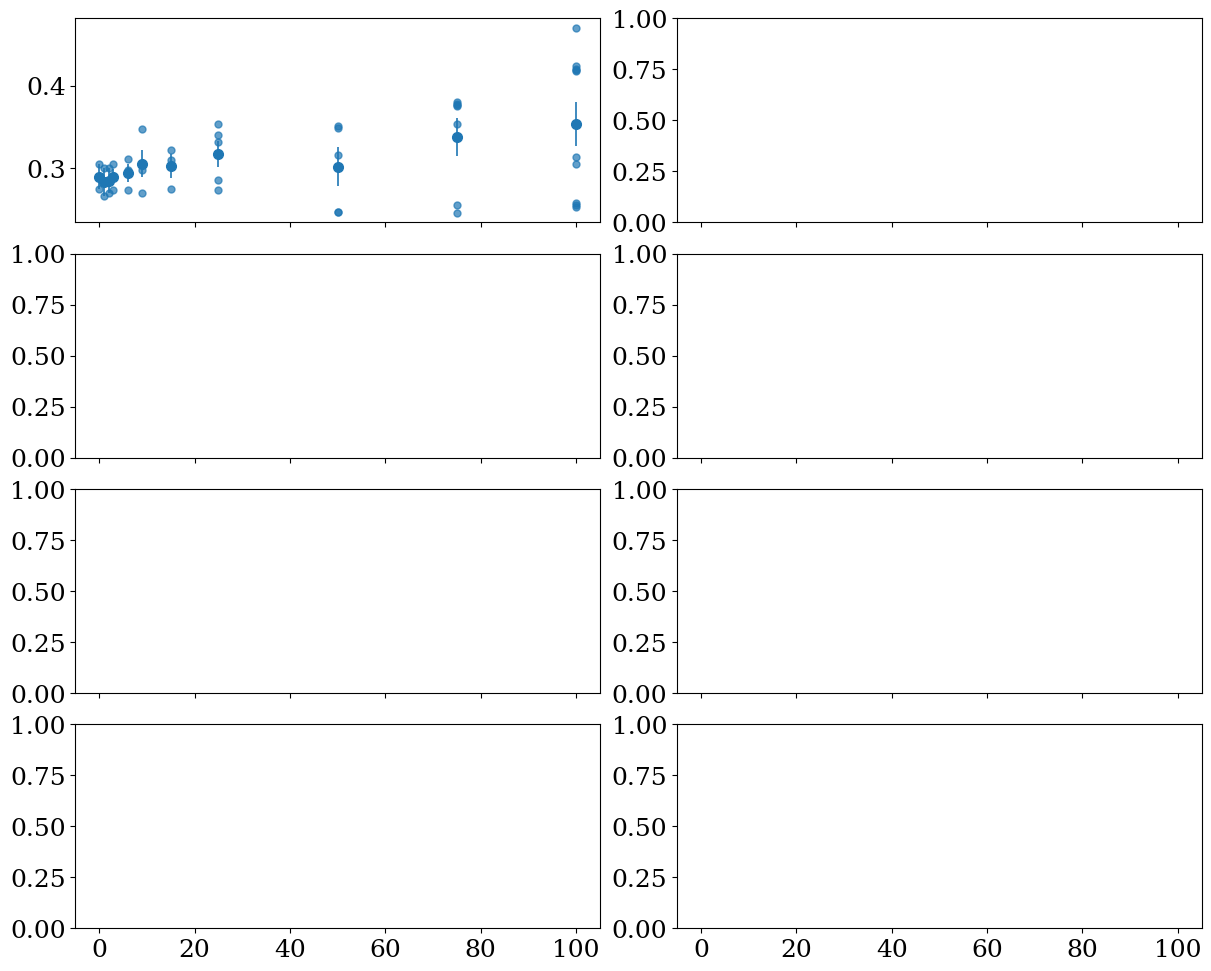

In [3]:
# ----------------------------------------------------------------------
# 1. Configuration – one entry per data set
# ----------------------------------------------------------------------
DATASETS = {
    "WT": {
        "label": "aSyn WT",
        "color": "C0",
        "marker": "o",
        "mean_marker": "o",
        "sample_asyn": {
            "BII_S9": 0.0,
            "BIV_S1": 1,
            "BIV_S2": 2,
            "BIV_S3": 3,
            "BIV_S4": 6,
            "BIV_S5": 9,
            "BIV_S6": 15,
            "BIV_S7": 25,
            "BIV_S8": 50,
            "BIV_S9": 75,
            "BIV_S10": 100,
        },
        "best_fits": BM29.best_fits,
    },
    "A124T": {
        "label": "aSyn A124T",
        "color": "C1",
        "marker": "s",
        "mean_marker": "s",
        "sample_asyn": {
            "BIV_S21": 1.0,
            "BIV_S22": 2.0,
            "BIV_S23": 3.0,
            "BIV_S24": 6.0,
            "BIV_S25": 9.0,
            "BIV_S26": 15.0,
            "BIV_S27": 25.0,
            "BIV_S28": 50.0,
            "BIV_S29": 75.0,
            "BIV_S30": 100.0,
        },
        "best_fits": BM29.best_fits,
    },
}

# ----------------------------------------------------------------------
# 2. Helper functions (equal weighting)
# ----------------------------------------------------------------------
def linear(x, m, n):
    return m * x + n


def simple_mean(values):
    """Ordinary arithmetic mean."""
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.nan
    return np.mean(values)


def simple_mean_err(values):
    """
    Standard error of the mean (SEM).
    Returns NaN when fewer than 2 points are available.
    """
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        return np.nan
    return np.std(values, ddof=1) / np.sqrt(n)


def collect_edp_metrics(best_fits, sample_asyn):
    """Return list of records for one dataset."""
    records = []
    for sample, asyn_conc in sample_asyn.items():
        if sample not in best_fits:
            continue
        # Note the key name used in your current code
        for cfg_id, params in best_fits[sample]["ULV_spheric_asym_C4"].items():
            edp_params = params[2:8]
            edp_tot, edp_hg_tot, edp_tg, edp_hg_asym, edp_hg_tg = fit.EDP_analysis(edp_params)

            records.append({
                "sample": sample,
                "aSyn": asyn_conc,
                "EDP_tot": edp_tot,
                "EDP_hg_tot": edp_hg_tot,
                "EDP_tg": abs(edp_tg),
                "EDP_hg_asym": edp_hg_asym,
                "EDP_hg_tg": edp_hg_tg,
                "R": params[0],
                "sigma_R": params[1],
                "z_h": params[7],
            })
    return records


def aggregate_by_concentration(records):
    """Simple (unweighted) means + SEM grouped by aSyn concentration."""
    groups = defaultdict(list)
    for r in records:
        groups[r["aSyn"]].append(r)

    metrics = ["EDP_tot", "EDP_hg_tot", "EDP_tg", "EDP_hg_asym",
               "EDP_hg_tg", "z_h", "R", "sigma_R"]

    means, mean_errs = {}, {}
    concentrations = sorted(groups.keys())

    for metric in metrics:
        m_list, e_list = [], []
        for conc in concentrations:
            vals = np.array([r[metric] for r in groups[conc]])
            m_list.append(simple_mean(vals))
            e_list.append(simple_mean_err(vals))
        means[metric] = np.array(m_list)
        mean_errs[metric] = np.array(e_list)

    return concentrations, means, mean_errs


# ----------------------------------------------------------------------
# 3. Collect data for every dataset
# ----------------------------------------------------------------------
all_data = {}

for ds_name, ds in DATASETS.items():
    records = collect_edp_metrics(ds["best_fits"], ds["sample_asyn"])
    if not records:
        print(f"Warning: no records for {ds_name}")
        continue

    aSyn_all = np.array([r["aSyn"] for r in records])
    data_map = {
        "EDP_tot":     np.array([r["EDP_tot"]     for r in records]),
        "EDP_hg_tot":  np.array([r["EDP_hg_tot"]  for r in records]),
        "EDP_tg":      np.array([r["EDP_tg"]      for r in records]),
        "EDP_hg_asym": np.array([r["EDP_hg_asym"] for r in records]),
        "EDP_hg_tg":   np.array([r["EDP_hg_tg"]   for r in records]),
        "z_h":         np.array([r["z_h"]         for r in records]),
        "R":           np.array([r["R"]           for r in records]),
        "sigma_R":     np.array([r["sigma_R"]     for r in records]),
    }
    aSyn_means, means, mean_errs = aggregate_by_concentration(records)

    all_data[ds_name] = {
        "records": records,
        "aSyn_all": aSyn_all,
        "data_map": data_map,
        "aSyn_means": aSyn_means,
        "means": means,
        "mean_errs": mean_errs,
        "style": ds,
    }

# ----------------------------------------------------------------------
# 4. Plotting
# ----------------------------------------------------------------------
titles = [
    ("EDP_tot",     "(a) Total EDP integral",                     r"$(\Omega_1 + \Omega_2 + \Omega_3)$ [nm]"),
    ("EDP_hg_tot",  "(b) Lipid head groups EDP integral",         r"$(\Omega_1 + \Omega_3)$ [nm]"),
    ("EDP_tg",      "(c) Lipid tail group EDP integral",          r"$|\Omega_2|$ [nm]"),
    ("EDP_hg_asym", "(d) Lipid head groups EDP integral asymmetry", r"$\frac{|\Omega_1-\Omega_3|}{\Omega_1+\Omega_3}$"),
    ("EDP_hg_tg",   "(e) Head to tail groups EDP integral ratio", r"$\frac{\Omega_1+\Omega_3}{|\Omega_2|}$"),
    ("z_h",         "(f) Fitted head group position $z_h$",       r"$z_h$ [nm]"),
    ("R",           "(g) Fitted radius $R$",                      r"$R$ [nm]"),
    ("sigma_R",     "(h) Fitted polydispersity $\sigma_R$",       r"$\sigma_R$ [nm]"),
]

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
})

fig, axes = plt.subplots(4, 2, figsize=(12, 9.6), sharex=True, constrained_layout=True)
axes = axes.flatten()

for ax, (key, title, ylabel) in zip(axes, titles):
    for ds_name, data in all_data.items():
        style = data["style"]
        col   = style["color"]

        # individual points
        ax.plot(data["aSyn_all"], data["data_map"][key],
                ls="None", marker=style["marker"], markersize=5,
                color=col, alpha=0.7,
                label=style["label"] if key == "EDP_tot" else None)

        # unweighted means + SEM error bars
        ax.errorbar(data["aSyn_means"], data["means"][key], data["mean_errs"][key],
                    color=col, ls="None", marker=style["mean_marker"],
                    markersize=7, zorder=5, elinewidth=1.2)

        # linear fit to the means
        # (ignore NaN error bars by using only finite points)
        mask = np.isfinite(data["mean_errs"][key])
        if np.sum(mask) >= 2:
            popt, pcov = curve_fit(
                linear,
                data["aSyn_means"][mask], data["means"][key][mask],
                sigma=data["mean_errs"][key][mask],
                maxfev=20000, p0=[0.0, 0.0]
            )
            perr = np.sqrt(np.diag(pcov))
            print(f"{ds_name} – {key}:  m = {popt[0]:.4g} ± {perr[0]:.4g},  "
                  f"n = {popt[1]:.4g} ± {perr[1]:.4g}")

            ax.plot(data["aSyn_means"], linear(data["aSyn_means"], *popt),
                    color=col, alpha=0.6, linewidth=1.0)

    ax.set_title(title, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.grid(True)

axes[0].legend(fontsize=11, frameon=True)

for ax in axes[-2:]:
    ax.set_xlabel("aSyn concentration [µM]", fontsize=14)

# ----------------------------------------------------------------------
# 5. Save / show
# ----------------------------------------------------------------------
# target_folder = Path("figures")
# target_folder.mkdir(exist_ok=True)
# fig.savefig(target_folder / "EDP_metrics_spherical_WT_vs_A124T.png",
#             dpi=600, bbox_inches="tight")
plt.show()